# UMAMI Urban Heat V3.1 — Multi-Task Training with Mode-Collapse Fix

This notebook is a V3.1 retrain of the V2.1/V3 model. It uses the same
12-channel input format and 3 multi-task heads, the same 11,844-patch corpus,
and the same ResNet34-UNet architecture, but fixes mode collapse identified
in V3 inference (output had near-zero building-vs-canopy contrast).

**Mode-collapse fixes vs V2.1:**

1. **LOSS_WEIGHTS** — `tair_sparse` reduced from 10.0 to 1.0. The previous 10×
   weight on a 1-cell-per-patch sparse signal dominated the dense T_mrt loss
   and pushed the model to predict ~mean Tair everywhere.
2. **T_mrt loss** — replaced MSE with L1 + variance-preservation term. The
   variance term directly penalises predictions whose per-patch std is
   smaller than the label's per-patch std (i.e. punishes flat output).
3. **Flat-patch filter** — train-split patches with label std < 1 °C are
   dropped (they reinforce mode collapse). Val/test splits keep them for
   honest evaluation.
4. **Output-health metric** — per-epoch, sample 20 high-variance val patches,
   log median ratio pred_std / label_std. Collapse appears as this ratio
   dropping below 0.5; healthy training stays above 0.7.

**Drive layout (no collision with existing v3):**
- READ: `gdrive:UMAMI/urban_heat_v3/patches_v21.tar` (corpus, reused)
- READ: `gdrive:UMAMI/urban_heat_v3/models/best_model_v2.pt` (warm-start)
- WRITE: `gdrive:UMAMI/urban_heat_v31/models/` (new outputs)
- WRITE: `gdrive:UMAMI/urban_heat_v31/manifest_v31.parquet` (with label_std column)


## 1 — Setup (Drive mount + dependencies)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 1.5 — Extract patches_v21.tar from Drive to local /content

Drive mount is fine for the 30 GB single-file copy (saturates ~50-100 MB/s on Colab) but terrible for the per-iteration random-access reads of 8,440 .npz files during training. We copy + extract once at the start so DataLoader hits Colab's local SSD instead.

This step takes ~5-10 minutes the first time; subsequent restarts of the same Colab VM skip it (the `if Path('/content/patches_v21').exists()` guard).

In [2]:
import time, shutil
from pathlib import Path

DRIVE_TAR = Path('/content/drive/MyDrive/UMAMI/urban_heat_v3/patches_v21.tar')
LOCAL_TAR = Path('/content/patches_v21.tar')
LOCAL_PATCHES = Path('/content/patches_v21')

if LOCAL_PATCHES.exists() and any(LOCAL_PATCHES.glob('*.npz')):
    n = len(list(LOCAL_PATCHES.glob('*.npz')))
    print(f'patches already extracted at {LOCAL_PATCHES} ({n:,} files) — skipping')
else:
    if not DRIVE_TAR.exists():
        raise FileNotFoundError(f'expected {DRIVE_TAR} on Drive — did the upload from the server complete?')

    if not LOCAL_TAR.exists():
        t0 = time.time()
        print(f'copying {DRIVE_TAR.name} → /content/ ({DRIVE_TAR.stat().st_size / 1e9:.1f} GB) …')
        shutil.copyfile(DRIVE_TAR, LOCAL_TAR)
        print(f'  copy done in {time.time()-t0:.0f}s')
    else:
        print(f'using existing {LOCAL_TAR}')

    t0 = time.time()
    print(f'extracting {LOCAL_TAR} → /content/ …')
    !tar -xf {LOCAL_TAR} -C /content/
    print(f'  extract done in {time.time()-t0:.0f}s')
    n = len(list(LOCAL_PATCHES.glob('*.npz')))
    print(f'  {n:,} .npz files in {LOCAL_PATCHES}')

    # Free disk: the tar is ~30 GB and we don't need it after extraction
    LOCAL_TAR.unlink(missing_ok=True)
    print(f'  removed local tar to free disk')

copying patches_v21.tar → /content/ (32.6 GB) …
  copy done in 499s
extracting /content/patches_v21.tar → /content/ …
  extract done in 86s
  11,844 .npz files in /content/patches_v21
  removed local tar to free disk


In [3]:
# Drive paths — V3.1 OUTPUTS to a NEW folder; corpus + warm-start READ from v3.
# This means no existing file on Drive is overwritten by this notebook.
DRIVE_ROOT = Path('/content/drive/MyDrive/UMAMI/urban_heat_v31')  # NEW
V3_ROOT    = Path('/content/drive/MyDrive/UMAMI/urban_heat_v3')   # READ-ONLY source

# Patches were extracted to local /content in cell 1.5 above (same tarball as v3).
PATCHES_DIR   = Path('/content/patches_v21')
MANIFEST_PATH = PATCHES_DIR / 'manifest.parquet'

# V2 warm-start lives in v3 — reuse, don't copy.
V2_CKPT_PATH = V3_ROOT / 'models' / 'best_model_v2.pt'

# V3.1 outputs land in the NEW folder; make sure it exists.
OUT_DIR = DRIVE_ROOT / 'models'
OUT_DIR.mkdir(parents=True, exist_ok=True)

# V2.1 channel order — must match patch_builder.CHANNEL_ORDER (NOT changed for V3.1).
CHANNEL_ORDER = (
    'dsm_corrected', 'cdsm', 'albedo',
    'sin_alt', 'alt_norm',
    'svf', 'building_density', 'tree_distance',
    'aspect_sin', 'aspect_cos', 'shadow_fraction',
    'era5_tair_c',
)
NUM_CHANNELS = len(CHANNEL_ORDER)
assert NUM_CHANNELS == 12

HEAD_NAMES = ('tmrt', 'lst', 'tair_sparse')
NUM_HEADS = len(HEAD_NAMES)

# V3.1 FIX 1 — equalise tair_sparse from 10.0 (V2.1) to 1.0. The 10x weight on
# a ~1-cell-per-patch sparse signal dominated the dense T_mrt loss and forced
# the model to predict ~mean Tair everywhere (mode collapse).
LOSS_WEIGHTS = {'tmrt': 1.0, 'lst': 0.5, 'tair_sparse': 1.0}

# V3.1 FIX 3 — drop training patches with near-constant T_mrt labels (std < this
# threshold). These patches teach the model "predict constant when in doubt"
# and reinforce mode collapse. Val/test splits keep all patches for honesty.
MIN_TRAIN_LABEL_STD_C = 1.0  # °C


In [5]:
!pip install -q segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 13.8 MB/s eta 0:00:00


In [6]:
import os
import json
import time
import math
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'device={DEVICE}, cuda_name={torch.cuda.get_device_name() if DEVICE.type == "cuda" else "-"}')

device=cuda, cuda_name=NVIDIA A100-SXM4-80GB


## 2 — Data loading

In [7]:
manifest = pd.read_parquet(MANIFEST_PATH)
print(f'manifest rows: {len(manifest):,}')
print(f'unique V2 patches: {manifest["v2_patch_id"].nunique()}')
print(f'unique temporal combos: {manifest[["doy", "hour"]].drop_duplicates().shape[0]}')
print()
print(f'has_tmrt        : {int(manifest["has_tmrt"].sum())} / {len(manifest)}')
print(f'has_lst         : {int(manifest["has_lst"].sum())} / {len(manifest)}')
print(f'num_sensors > 0 : {int((manifest["num_sensors_in_patch"] > 0).sum())} / {len(manifest)}')
print()
# Drop rows without T_mrt — those are useless for V2.1's primary signal
manifest = manifest[manifest['has_tmrt']].reset_index(drop=True)
print(f'after dropping has_tmrt=False: {len(manifest):,} rows')

manifest rows: 11,844
unique V2 patches: 987
unique temporal combos: 12

has_tmrt        : 11844 / 11844
has_lst         : 0 / 11844
num_sensors > 0 : 0 / 11844

after dropping has_tmrt=False: 11,844 rows


## 2.5 — Precompute T_mrt label std per patch (offline, once)

Reads every .npz once, computes std of finite T_mrt cells, writes a new
`manifest_v31.parquet` with a `label_std` column. This lets cell 9 filter
the train split to non-flat patches.

Takes ~3-5 minutes on Colab CPU; cached afterward.


In [8]:
import multiprocessing as mp
from pathlib import Path

MANIFEST_V31_PATH = PATCHES_DIR / 'manifest_v31.parquet'

def _compute_std(npz_path_str: str) -> float:
    """Compute std of finite T_mrt cells in one .npz patch."""
    try:
        with np.load(npz_path_str) as d:
            t = d['tmrt'].astype(np.float32)
        m = np.isfinite(t) & (t > -100) & (t < 1000)
        if m.sum() < 100:
            return 0.0
        return float(t[m].std())
    except Exception:
        return 0.0

if MANIFEST_V31_PATH.exists():
    manifest_v31 = pd.read_parquet(MANIFEST_V31_PATH)
    print(f'cached manifest_v31 loaded: {len(manifest_v31):,} rows')
else:
    npz_paths = [str(PATCHES_DIR / Path(p).name) for p in manifest['npz_path']]
    print(f'computing label std for {len(npz_paths):,} patches with {mp.cpu_count()} workers...')
    t0 = time.time()
    with mp.Pool(processes=min(mp.cpu_count(), 8)) as pool:
        stds = pool.map(_compute_std, npz_paths, chunksize=64)
    print(f'  done in {time.time()-t0:.0f}s')

    manifest_v31 = manifest.copy()
    manifest_v31['label_std'] = stds
    manifest_v31.to_parquet(MANIFEST_V31_PATH)

    # Mirror to Drive for traceability (small file, ~few MB)
    try:
        drive_copy = DRIVE_ROOT / 'manifest_v31.parquet'
        manifest_v31.to_parquet(drive_copy)
        print(f'  also wrote {drive_copy}')
    except Exception as e:
        print(f'  (Drive copy skipped: {e})')

print()
print('label_std distribution:')
print(manifest_v31['label_std'].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).to_string())
flat = int((manifest_v31['label_std'] < MIN_TRAIN_LABEL_STD_C).sum())
print(f'\npatches with std < {MIN_TRAIN_LABEL_STD_C} °C: {flat:,} ({100*flat/len(manifest_v31):.1f}%) — will drop from TRAIN split only')

manifest = manifest_v31  # downstream cells use this enriched manifest


computing label std for 11,844 patches with 12 workers...
  done in 15s
  also wrote /content/drive/MyDrive/UMAMI/urban_heat_v31/manifest_v31.parquet

label_std distribution:
count    11844.000000
mean         3.202418
std          2.769727
min          0.000000
5%           0.000000
25%          0.026986
50%          2.729230
75%          5.584028
95%          7.770494
max         10.431520

patches with std < 1.0 °C: 3,673 (31.0%) — will drop from TRAIN split only


In [9]:
# Train/val/test split — by V2 patch_id so the same geographic location
# never appears in both train and test. Hold out d306_h13 examples
# explicitly in test to verify the catastrophic combo is fixed.
rng = np.random.default_rng(seed=42)
all_v2_ids = manifest['v2_patch_id'].unique()
rng.shuffle(all_v2_ids)
n_test = int(len(all_v2_ids) * 0.10)
n_val = int(len(all_v2_ids) * 0.10)
test_ids = set(all_v2_ids[:n_test])
val_ids = set(all_v2_ids[n_test:n_test + n_val])
train_ids = set(all_v2_ids[n_test + n_val:])

manifest['split'] = manifest['v2_patch_id'].apply(
    lambda pid: 'train' if pid in train_ids else 'val' if pid in val_ids else 'test'
)

# V3.1 FIX 3 — DROP flat-label patches from TRAIN only. Keep them in val/test
# for honest evaluation (a flat label is a real situation: water bodies,
# uniform shaded courtyards, etc.).
#
# SAFEGUARD: if filtering would drop > 40% of train patches, auto-relax the
# threshold by halving it (and warn). The alpha-ordered smoke test on the
# server showed some v2_patch_id families have 100% flat instances; if those
# clusters dominate train, a naive 1.0 °C threshold could be too aggressive.
MAX_DROP_FRAC = 0.40

def _apply_filter(threshold_c: float):
    mask = (manifest['split'] == 'train') & (manifest['label_std'] < threshold_c)
    return int(mask.sum()), mask

n_train_before = int((manifest['split'] == 'train').sum())
threshold = MIN_TRAIN_LABEL_STD_C
n_drop, flat_mask = _apply_filter(threshold)
drop_frac = n_drop / max(n_train_before, 1)

while drop_frac > MAX_DROP_FRAC and threshold > 0.05:
    new_threshold = threshold / 2
    print(f'WARN: threshold={threshold:.3f}°C would drop {n_drop:,} / {n_train_before:,} '
          f'train patches ({100*drop_frac:.1f}% > {100*MAX_DROP_FRAC:.0f}%); relaxing to {new_threshold:.3f}°C')
    threshold = new_threshold
    n_drop, flat_mask = _apply_filter(threshold)
    drop_frac = n_drop / max(n_train_before, 1)

EFFECTIVE_TRAIN_STD_THRESHOLD = threshold
print(f'final flat-patch threshold: {threshold:.3f} °C  →  dropping {n_drop:,} ({100*drop_frac:.1f}%) of train')
manifest = manifest[~flat_mask].reset_index(drop=True)
n_train_after = int((manifest['split'] == 'train').sum())
print(f'  train: {n_train_before:,} → {n_train_after:,}')

print()
print(manifest['split'].value_counts())
print()
print('d306_h13 distribution:')
print(manifest[(manifest['doy'] == 306) & (manifest['hour'] == 13)]['split'].value_counts())


final flat-patch threshold: 1.000 °C  →  dropping 3,014 (31.8%) of train
  train: 9,492 → 6,478

split
train    6478
test     1176
val      1176
Name: count, dtype: int64

d306_h13 distribution:
split
train    454
test      98
val       98
Name: count, dtype: int64


In [10]:
class V21PatchDataset(Dataset):
    """Loads (input_12ch, tmrt, lst, tair_sparse) from .npz files.

    Labels arrive with NaN cells where supervision is missing.
    The training loop's loss handles those.
    """
    def __init__(self, manifest_df: pd.DataFrame, patches_dir: Path):
        self.df = manifest_df.reset_index(drop=True)
        self.patches_dir = Path(patches_dir)
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        npz_path = self.patches_dir / Path(row['npz_path']).name
        with np.load(npz_path) as data:
            inp = data['input'].astype(np.float32)        # (12, H, W)
            tmrt = data['tmrt'].astype(np.float32)        # (H, W)
            lst = data['lst'].astype(np.float32)          # (H, W)
            tair = data['tair_sparse'].astype(np.float32) # (H, W)
        return {
            'input': torch.from_numpy(inp),
            'tmrt': torch.from_numpy(tmrt),
            'lst': torch.from_numpy(lst),
            'tair_sparse': torch.from_numpy(tair),
            'patch_id': row['patch_id'],
            'doy': int(row['doy']),
            'hour': int(row['hour']),
        }

train_ds = V21PatchDataset(manifest[manifest['split'] == 'train'], PATCHES_DIR)
val_ds = V21PatchDataset(manifest[manifest['split'] == 'val'], PATCHES_DIR)
test_ds = V21PatchDataset(manifest[manifest['split'] == 'test'], PATCHES_DIR)
print(f'train={len(train_ds)}, val={len(val_ds)}, test={len(test_ds)}')

# Quick sanity check on shapes
sample = train_ds[0]
for k, v in sample.items():
    if torch.is_tensor(v):
        print(f'  {k}: shape={tuple(v.shape)}, dtype={v.dtype}')
    else:
        print(f'  {k}: {v}')

train=6478, val=1176, test=1176
  input: shape=(12, 512, 512), dtype=torch.float32
  tmrt: shape=(512, 512), dtype=torch.float32
  lst: shape=(512, 512), dtype=torch.float32
  tair_sparse: shape=(512, 512), dtype=torch.float32
  patch_id: patch_0012_d015_h09
  doy: 15
  hour: 9


In [11]:
BATCH_SIZE = 16
NUM_WORKERS = 4

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
)

## 3 — Model: ResNet34-UNet with 3 multi-task heads + warm-start

In [13]:
# Create the model — V21/V31 notebook is missing this step; warm-start expects it.
# ResNet34-UNet with 12 input channels and 3 output heads (tmrt, lst, tair_sparse).
# encoder_weights='imagenet' gives a better init than from-scratch.
model = smp.Unet(
    encoder_name='resnet34',
    encoder_weights='imagenet',
    in_channels=NUM_CHANNELS,   # 12, from cell 5
    classes=NUM_HEADS,           # 3, from cell 5
)
print(f"model created: {sum(p.numel() for p in model.parameters()):,} parameters")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

model created: 24,464,883 parameters


In [14]:
# Warm-start from V2 best.pt — extend first conv to 12 channels,
# zero-init slot 11 (ERA5) so V2 behaviour is preserved at epoch 0
if V2_CKPT_PATH.exists():
    print(f'warm-starting from {V2_CKPT_PATH}')
    raw = torch.load(V2_CKPT_PATH, map_location='cpu')
    # V2 wraps weights under 'model'; other checkpoints use 'state_dict' or are flat.
    if isinstance(raw, dict) and 'model' in raw and isinstance(raw['model'], dict):
        v2_state = raw['model']
        print(f"  unwrapped from 'model' key (V2 epoch={raw.get('epoch','?')}, "
              f"val_rmse={raw.get('best_val_rmse', float('nan')):.3f})")
    elif isinstance(raw, dict) and 'state_dict' in raw:
        v2_state = raw['state_dict']
    else:
        v2_state = raw

    # First conv: V2 was 11 in-channels; V2.1 is 12. Extend along dim 1.
    v2_first_conv = v2_state.get('encoder.conv1.weight')
    if v2_first_conv is not None:
        n_out, n_in_v2, k1, k2 = v2_first_conv.shape
        if n_in_v2 == 11:
            new_conv = torch.zeros(n_out, NUM_CHANNELS, k1, k2)
            new_conv[:, :11] = v2_first_conv
            new_conv[:, 11] = 0.0  # ERA5 channel — start neutral
            v2_state['encoder.conv1.weight'] = new_conv
            print(f'  extended encoder.conv1 from (11) to (12) input channels')
    else:
        print('  WARNING: encoder.conv1.weight not found — first-conv extension skipped')

    # Final segmentation head: V2 had classes=1, V2.1 has classes=3 — drop
    # the V2 head weights (if any) so SMP's random-init is used
    drop = [k for k in v2_state if k.startswith('segmentation_head')]
    for k in drop:
        del v2_state[k]
    print(f'  dropped {len(drop)} segmentation_head keys (incompatible shapes)')

    missing, unexpected = model.load_state_dict(v2_state, strict=False)
    print(f'  loaded; missing={len(missing)}, unexpected={len(unexpected)}')
    if len(missing) <= 5:
        print(f'  missing keys: {missing}')
    if 0 < len(unexpected) <= 5:
        print(f'  unexpected keys: {unexpected}')
else:
    print(f'V2 checkpoint not found at {V2_CKPT_PATH} — training from scratch')

model = model.to(DEVICE)

warm-starting from /content/drive/MyDrive/UMAMI/urban_heat_v3/models/best_model_v2.pt
  unwrapped from 'model' key (V2 epoch=11, val_rmse=4.751)
  extended encoder.conv1 from (11) to (12) input channels
  dropped 0 segmentation_head keys (incompatible shapes)
  loaded; missing=124, unexpected=39


In [ ]:
# Warm-start from V2 best.pt — extend first conv to 12 channels,
# zero-init slot 11 (ERA5) so V2 behaviour is preserved at epoch 0
if V2_CKPT_PATH.exists():
    print(f'warm-starting from {V2_CKPT_PATH}')
    v2_state = torch.load(V2_CKPT_PATH, map_location='cpu')
    if 'state_dict' in v2_state:
        v2_state = v2_state['state_dict']

    # First conv: V2 was 11 in-channels; V2.1 is 12. Extend along dim 1.
    v2_first_conv = v2_state.get('encoder.conv1.weight')
    if v2_first_conv is not None:
        n_out, n_in_v2, k1, k2 = v2_first_conv.shape
        if n_in_v2 == 11:
            new_conv = torch.zeros(n_out, NUM_CHANNELS, k1, k2)
            new_conv[:, :11] = v2_first_conv
            new_conv[:, 11] = 0.0  # ERA5 channel — start neutral
            v2_state['encoder.conv1.weight'] = new_conv
            print(f'  extended encoder.conv1 from (11) to (12) input channels')

    # Final segmentation head: V2 had classes=1, V2.1 has classes=3 — drop
    # the V2 head weights so SMP's random-init is used
    drop = [k for k in v2_state if k.startswith('segmentation_head')]
    for k in drop:
        del v2_state[k]
    print(f'  dropped {len(drop)} segmentation_head keys (incompatible shapes)')

    missing, unexpected = model.load_state_dict(v2_state, strict=False)
    print(f'  loaded; missing={len(missing)}, unexpected={len(unexpected)}')
else:
    print(f'V2 checkpoint not found at {V2_CKPT_PATH} — training from scratch')

model = model.to(DEVICE)

warm-starting from /content/drive/MyDrive/UMAMI/urban_heat_v3/models/best_model_v2.pt
  dropped 0 segmentation_head keys (incompatible shapes)
  loaded; missing=232, unexpected=7


In [15]:
# Sanity-check: did V2's encoder weights actually land?
v2_first = raw['model']['encoder.conv1.weight']
model_first = model.encoder.conv1.weight.data.cpu()
print(f"V2 first conv first 11 channels mean abs : {v2_first.abs().mean().item():.4f}")
print(f"Model first 11 channels mean abs        : {model_first[:, :11].abs().mean().item():.4f}")
print(f"Model channel 11 (ERA5 — should be ~0)  : {model_first[:, 11].abs().mean().item():.4e}")
print(f"Match V2 ↔ model on channels 0-10       : "
      f"{(v2_first - model_first[:, :11].cpu()).abs().max().item():.2e}  "
      f"(should be 0 if warm-start worked)")

# Spot-check a layer1 weight
v2_l1 = raw['model'].get('encoder.layer1.0.conv1.weight')
m_l1 = model.encoder.layer1[0].conv1.weight.data.cpu()
if v2_l1 is not None:
    print(f"layer1.0.conv1 match: {(v2_l1 - m_l1).abs().max().item():.2e}")

V2 first conv first 11 channels mean abs : 0.0294
Model first 11 channels mean abs        : 0.0320
Model channel 11 (ERA5 — should be ~0)  : 0.0000e+00


RuntimeError: The size of tensor a (12) must match the size of tensor b (11) at non-singleton dimension 1

In [16]:
import torch
raw_fresh = torch.load(V2_CKPT_PATH, map_location='cpu')
v2_orig = raw_fresh['model']['encoder.conv1.weight']  # original (64, 11, 7, 7)
m = model.encoder.conv1.weight.data.cpu()               # current (64, 12, 7, 7)

print(f"V2 conv1 shape   : {tuple(v2_orig.shape)}")
print(f"Model conv1 shape: {tuple(m.shape)}")
print(f"max |V2 - model[:, :11]|  : {(v2_orig - m[:, :11]).abs().max().item():.2e}  (should be 0)")
print(f"model channel 11 max abs  : {m[:, 11].abs().max().item():.2e}  (should be 0)")

# Spot-check a deep encoder layer
v2_l4 = raw_fresh['model'].get('encoder.layer4.0.conv1.weight')
m_l4 = model.encoder.layer4[0].conv1.weight.data.cpu()
if v2_l4 is not None:
    print(f"max |V2 - model| layer4.0.conv1: {(v2_l4 - m_l4).abs().max().item():.2e}")

V2 conv1 shape   : (64, 11, 7, 7)
Model conv1 shape: (64, 12, 7, 7)
max |V2 - model[:, :11]|  : 0.00e+00  (should be 0)
model channel 11 max abs  : 0.00e+00  (should be 0)
max |V2 - model| layer4.0.conv1: 0.00e+00


In [17]:
print("=== Missing keys (first 10) — model expects these, V2 didn't provide ===")
for k in missing[:10]: print(f"  {k}")
print(f"\n=== Unexpected keys (first 10) — V2 had, model didn't want ===")
for k in unexpected[:10]: print(f"  {k}")
print(f"\n=== Sample V2 keys: {list(v2_state.keys())[:5]}")
print(f"=== Sample model keys: {list(model.state_dict().keys())[:5]}")

=== Missing keys (first 10) — model expects these, V2 didn't provide ===
  encoder.bn1.running_mean
  encoder.bn1.running_var
  encoder.layer1.0.bn1.running_mean
  encoder.layer1.0.bn1.running_var
  encoder.layer1.0.bn2.running_mean
  encoder.layer1.0.bn2.running_var
  encoder.layer1.1.bn1.running_mean
  encoder.layer1.1.bn1.running_var
  encoder.layer1.1.bn2.running_mean
  encoder.layer1.1.bn2.running_var

=== Unexpected keys (first 10) — V2 had, model didn't want ===
  dec4.up.weight
  dec4.up.bias
  dec4.conv.0.weight
  dec4.conv.1.weight
  dec4.conv.1.bias
  dec4.conv.3.weight
  dec4.conv.4.weight
  dec4.conv.4.bias
  dec3.up.weight
  dec3.up.bias

=== Sample V2 keys: ['encoder.conv1.weight', 'encoder.bn1.weight', 'encoder.bn1.bias', 'encoder.layer1.0.conv1.weight', 'encoder.layer1.0.bn1.weight']
=== Sample model keys: ['encoder.conv1.weight', 'encoder.bn1.weight', 'encoder.bn1.bias', 'encoder.bn1.running_mean', 'encoder.bn1.running_var']


## 4 — Multi-task NaN-aware loss

Each label channel may have NaN cells (no supervision). MSE is computed only over finite cells.

If a head has zero finite cells in a batch, that head's contribution is 0 (no gradient through that branch for this batch). This lets sparse signals (sensor Tair: ~1 finite cell per patch) coexist with dense signals (T_mrt: ~95% finite cells per patch) in one training loop.

In [18]:
def masked_mse(pred: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
    """Used unchanged for lst and tair_sparse heads."""
    mask = torch.isfinite(target)
    if mask.sum() == 0:
        return torch.tensor(0.0, device=pred.device, requires_grad=True)
    diff = pred[mask] - target[mask]
    return (diff ** 2).mean()


def tmrt_loss_v31(pred: torch.Tensor, target: torch.Tensor,
                  structure_threshold: float = 1.0,
                  variance_weight: float = 0.5) -> torch.Tensor:
    """V3.1 T_mrt loss = L1 + variance-preservation.

    pred, target: (B, H, W). target may contain NaN cells.

    L1 (per-patch averaged over valid pixels, then batch-averaged): more
    robust to outliers than MSE and less mean-seeking.

    Variance preservation: for each patch where the LABEL has spatial
    structure (per-patch std > structure_threshold °C), penalise predictions
    whose per-patch std falls below the label's. This directly fights mode
    collapse without distorting per-pixel calibration.

    All operations vectorised over batch — no Python loop.
    """
    mask = torch.isfinite(target)
    B = pred.shape[0]

    # Replace NaN-masked positions with zeros for arithmetic; reconcile via valid_count.
    pred_filled = torch.where(mask, pred, torch.zeros_like(pred))
    target_filled = torch.where(mask, target, torch.zeros_like(target))
    abs_diff = torch.where(mask, (pred - target).abs(), torch.zeros_like(pred))

    valid_count = mask.float().sum(dim=(-2, -1)).clamp(min=1)  # (B,)

    # ---- L1 per-patch (then batch mean) ----
    per_patch_l1 = abs_diff.sum(dim=(-2, -1)) / valid_count
    l1_loss = per_patch_l1.mean()

    # ---- Variance preservation per-patch ----
    pred_sum    = pred_filled.sum(dim=(-2, -1))
    target_sum  = target_filled.sum(dim=(-2, -1))
    pred_sumsq  = (pred_filled ** 2).sum(dim=(-2, -1))
    target_sumsq = (target_filled ** 2).sum(dim=(-2, -1))
    pred_mean   = pred_sum / valid_count
    target_mean = target_sum / valid_count
    pred_var    = (pred_sumsq / valid_count) - pred_mean ** 2
    target_var  = (target_sumsq / valid_count) - target_mean ** 2
    pred_std    = pred_var.clamp(min=1e-8).sqrt()
    target_std  = target_var.clamp(min=1e-8).sqrt()

    has_structure = (target_std > structure_threshold).float()  # (B,)
    var_gap = (target_std - pred_std).clamp(min=0.0)            # (B,) >=0 when collapsed
    n_struct = has_structure.sum().clamp(min=1.0)
    var_loss = (has_structure * var_gap).sum() / n_struct

    return l1_loss + variance_weight * var_loss


def multi_task_loss(pred_3ch: torch.Tensor, batch: dict) -> tuple[torch.Tensor, dict]:
    """pred_3ch: (B, 3, H, W) — channels in HEAD_NAMES order.

    V3.1: T_mrt uses new L1 + variance loss; LST and Tair keep masked MSE.
    """
    losses = {}
    losses['tmrt']        = tmrt_loss_v31(pred_3ch[:, 0], batch['tmrt'].to(pred_3ch.device, non_blocking=True))
    losses['lst']         = masked_mse(pred_3ch[:, 1], batch['lst'].to(pred_3ch.device, non_blocking=True))
    losses['tair_sparse'] = masked_mse(pred_3ch[:, 2], batch['tair_sparse'].to(pred_3ch.device, non_blocking=True))
    total = sum(LOSS_WEIGHTS[h] * losses[h] for h in HEAD_NAMES)
    return total, losses


## 5 — Training loop

In [19]:
EPOCHS = 100
LR = 1e-4
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 5.0

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

history = {'train_loss': [], 'val_loss': [],
           'val_rmse_tmrt': [], 'val_rmse_lst': [], 'val_rmse_tair': []}
best_val_rmse_tmrt = float('inf')
BEST_CKPT_PATH = OUT_DIR / 'v21_best.pt'

In [20]:
def epoch_pass(loader, training: bool) -> dict:
    """One pass over a loader. Returns per-head total SE and pixel counts."""
    model.train(training)  # True for train, False for inference
    accum_loss = 0.0
    se = {h: 0.0 for h in HEAD_NAMES}
    n  = {h: 0 for h in HEAD_NAMES}
    n_batches = 0
    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for batch in loader:
            x = batch['input'].to(DEVICE, non_blocking=True)
            pred = model(x)  # (B, 3, H, W)
            total, losses = multi_task_loss(pred, batch)
            if training:
                opt.zero_grad()
                total.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                opt.step()
            accum_loss += float(total.detach().cpu())
            n_batches += 1
            # Accumulate squared error per head for proper RMSE
            for i, h in enumerate(HEAD_NAMES):
                tgt = batch[h].to(DEVICE, non_blocking=True)
                mask = torch.isfinite(tgt)
                if mask.sum() > 0:
                    diff = pred[:, i][mask] - tgt[mask]
                    se[h] += float((diff ** 2).sum().detach().cpu())
                    n[h] += int(mask.sum().detach().cpu())
    rmse = {h: math.sqrt(se[h] / max(n[h], 1)) if n[h] > 0 else float('nan') for h in HEAD_NAMES}
    return {'loss': accum_loss / max(n_batches, 1), 'rmse': rmse, 'pixel_counts': n}

In [21]:
# V3.1 — output-health metric: per-epoch, sample physics-rich val patches and
# log median pred_std / label_std ratio. A healthy model has ratio > 0.7; mode
# collapse appears as ratio dropping toward 0. If we see < 0.5 for several
# consecutive epochs, the fix isn't working and we should stop early.
HEALTH_PATCH_TARGET_COUNT = 20
HEALTH_LABEL_STD_THRESHOLD = 5.0

# Pick 20 patches with high label_std from the VAL split (sorted by std desc, deterministic).
_health_pool = manifest[(manifest['split'] == 'val') & (manifest['label_std'] >= HEALTH_LABEL_STD_THRESHOLD)]
_health_pool = _health_pool.sort_values('label_std', ascending=False).head(HEALTH_PATCH_TARGET_COUNT)
print(f'output-health monitor: {len(_health_pool)} physics-rich val patches (median label_std={_health_pool["label_std"].median():.2f} °C)')

def output_health_check() -> float:
    """Run model on the health patches; return median pred_std / label_std ratio."""
    model.train(False)
    ratios = []
    with torch.no_grad():
        for _, row in _health_pool.iterrows():
            npz_path = PATCHES_DIR / Path(row['npz_path']).name
            with np.load(npz_path) as d:
                inp = torch.from_numpy(d['input'].astype(np.float32)).unsqueeze(0).to(DEVICE)
                tmrt_label = d['tmrt'].astype(np.float32)
            pred = model(inp)[0, 0].cpu().numpy()
            m = np.isfinite(tmrt_label) & (tmrt_label > -100) & (tmrt_label < 1000)
            if m.sum() < 1000: continue
            label_std = float(tmrt_label[m].std())
            pred_std  = float(pred[m].std())
            if label_std > 1e-3:
                ratios.append(pred_std / label_std)
    return float(np.median(ratios)) if ratios else float('nan')

history['health_ratio'] = []

for epoch in range(EPOCHS):
    t0 = time.time()
    train_stats = epoch_pass(train_loader, training=True)
    val_stats = epoch_pass(val_loader, training=False)
    scheduler.step()

    health = output_health_check()

    history['train_loss'].append(train_stats['loss'])
    history['val_loss'].append(val_stats['loss'])
    history['val_rmse_tmrt'].append(val_stats['rmse']['tmrt'])
    history['val_rmse_lst'].append(val_stats['rmse']['lst'])
    history['val_rmse_tair'].append(val_stats['rmse']['tair_sparse'])
    history['health_ratio'].append(health)

    elapsed = time.time() - t0
    health_marker = ('  HEALTHY' if health > 0.7 else
                     '  weak'    if health > 0.5 else
                     '  COLLAPSING' if health > 0.0 else
                     '  ?')
    print(
        f'epoch {epoch+1:3d}/{EPOCHS}  '
        f'train={train_stats["loss"]:.3f}  val={val_stats["loss"]:.3f}  '
        f'rmse[tmrt={val_stats["rmse"]["tmrt"]:.3f} '
        f'lst={val_stats["rmse"]["lst"]:.3f} '
        f'tair={val_stats["rmse"]["tair_sparse"]:.3f}]  '
        f'health={health:.3f}{health_marker}  '
        f'lr={scheduler.get_last_lr()[0]:.2e}  '
        f'{elapsed:.0f}s'
    )

    if val_stats['rmse']['tmrt'] < best_val_rmse_tmrt:
        best_val_rmse_tmrt = val_stats['rmse']['tmrt']
        torch.save({
            'epoch': epoch,
            'state_dict': model.state_dict(),
            'val_rmse_tmrt': best_val_rmse_tmrt,
            'health_ratio': health,
            'history': history,
        }, BEST_CKPT_PATH)
        print(f'  ↳ best so far ({best_val_rmse_tmrt:.3f} °C, health={health:.3f}); checkpointed')


output-health monitor: 20 physics-rich val patches (median label_std=9.48 °C)
epoch   1/100  train=25.234  val=24.119  rmse[tmrt=24.911 lst=nan tair=nan]  health=0.342  COLLAPSING  lr=1.00e-04  156s
  ↳ best so far (24.911 °C, health=0.342); checkpointed
epoch   2/100  train=22.532  val=21.916  rmse[tmrt=23.482 lst=nan tair=nan]  health=0.512  weak  lr=9.99e-05  155s
  ↳ best so far (23.482 °C, health=0.512); checkpointed
epoch   3/100  train=19.665  val=19.051  rmse[tmrt=20.749 lst=nan tair=nan]  health=0.659  weak  lr=9.98e-05  155s
  ↳ best so far (20.749 °C, health=0.659); checkpointed
epoch   4/100  train=16.757  val=17.428  rmse[tmrt=20.012 lst=nan tair=nan]  health=0.667  weak  lr=9.96e-05  155s
  ↳ best so far (20.012 °C, health=0.667); checkpointed
epoch   5/100  train=14.004  val=14.891  rmse[tmrt=18.185 lst=nan tair=nan]  health=0.856  HEALTHY  lr=9.94e-05  155s
  ↳ best so far (18.185 °C, health=0.856); checkpointed
epoch   6/100  train=11.107  val=12.194  rmse[tmrt=17.153 

## 6 — Evaluation on test set + per-temporal-combo breakdown

**Success criteria** (from `EVALUATION.md` / `IMPLEMENTATION_PLAN.md`):
- RMSE vs SOLWEIG ≤ **3.2 °C** on held-out test set (V2: 4.77 °C)
- d306_h13 RMSE ≤ **1.0 °C** (V2: 16.3 °C — the catastrophe)
- RMSE vs Landsat LST ≤ **3.5 °C**
- RMSE vs sensor Tair ≤ **2.5 °C**

In [22]:
# Reload best checkpoint
ckpt = torch.load(BEST_CKPT_PATH, map_location=DEVICE)
model.load_state_dict(ckpt['state_dict'])
model.train(False)
print(f'loaded best (epoch {ckpt["epoch"]+1}, val_rmse_tmrt={ckpt["val_rmse_tmrt"]:.3f})')

test_stats = epoch_pass(test_loader, training=False)
print()
print('=== test-set results ===')
for h in HEAD_NAMES:
    target = {'tmrt': 3.2, 'lst': 3.5, 'tair_sparse': 2.5}[h]
    rmse = test_stats['rmse'][h]
    px = test_stats['pixel_counts'][h]
    status = 'PASS' if rmse <= target else 'FAIL'
    print(f'  {h:14s}: RMSE={rmse:.3f} °C  (target ≤ {target}) {status}  [{px:,} px]')

loaded best (epoch 82, val_rmse_tmrt=3.610)

=== test-set results ===
  tmrt          : RMSE=3.537 °C  (target ≤ 3.2) FAIL  [277,337,964 px]
  lst           : RMSE=nan °C  (target ≤ 3.5) FAIL  [0 px]
  tair_sparse   : RMSE=nan °C  (target ≤ 2.5) FAIL  [0 px]


In [23]:
# Per-temporal-combo error breakdown — verify d306_h13 is fixed
test_df = manifest[manifest['split'] == 'test'].copy()
combo_se = {}
combo_n = {}
with torch.no_grad():
    for batch in test_loader:
        x = batch['input'].to(DEVICE, non_blocking=True)
        pred = model(x)[:, 0]  # tmrt head only for this analysis
        for i in range(len(batch['patch_id'])):
            tmrt_pred = pred[i].cpu().numpy()
            tmrt_true = batch['tmrt'][i].numpy()
            mask = np.isfinite(tmrt_true)
            if not mask.any():
                continue
            doy, hour = int(batch['doy'][i]), int(batch['hour'][i])
            key = (doy, hour)
            sse = float(((tmrt_pred[mask] - tmrt_true[mask]) ** 2).sum())
            combo_se[key] = combo_se.get(key, 0.0) + sse
            combo_n[key] = combo_n.get(key, 0) + int(mask.sum())

rows = []
for key in sorted(combo_se):
    rmse = math.sqrt(combo_se[key] / max(combo_n[key], 1))
    rows.append({'doy': key[0], 'hour': key[1], 'rmse_c': rmse,
                 'n_pixels': combo_n[key]})
combo_df = pd.DataFrame(rows).sort_values('rmse_c', ascending=False)
print(combo_df.to_string(index=False))
print()
if combo_df.empty:
    print('No test samples — cannot evaluate per-combo')
else:
    d306_row = combo_df[(combo_df['doy'] == 306) & (combo_df['hour'] == 13)]
    if not d306_row.empty:
        rmse = float(d306_row['rmse_c'].iloc[0])
        target = 1.0
        status = 'FIXED' if rmse <= target else 'STILL BROKEN'
        print(f'd306_h13 RMSE = {rmse:.3f} °C  (target ≤ {target}, V2 was 16.3) {status}')

 doy  hour   rmse_c  n_pixels
  15    15 4.529666  23111497
  15     9 4.369486  23111497
  46    13 4.325288  23111497
  46     9 3.977673  23111497
 306    13 3.760118  23111497
 356     9 3.585478  23111497
  15    13 3.222773  23111497
  15    11 3.215623  23111497
 356    15 3.187535  23111497
 356    11 2.990194  23111497
 356    13 2.762699  23111497
 306     9 1.232830  23111497

d306_h13 RMSE = 3.760 °C  (target ≤ 1.0, V2 was 16.3) STILL BROKEN


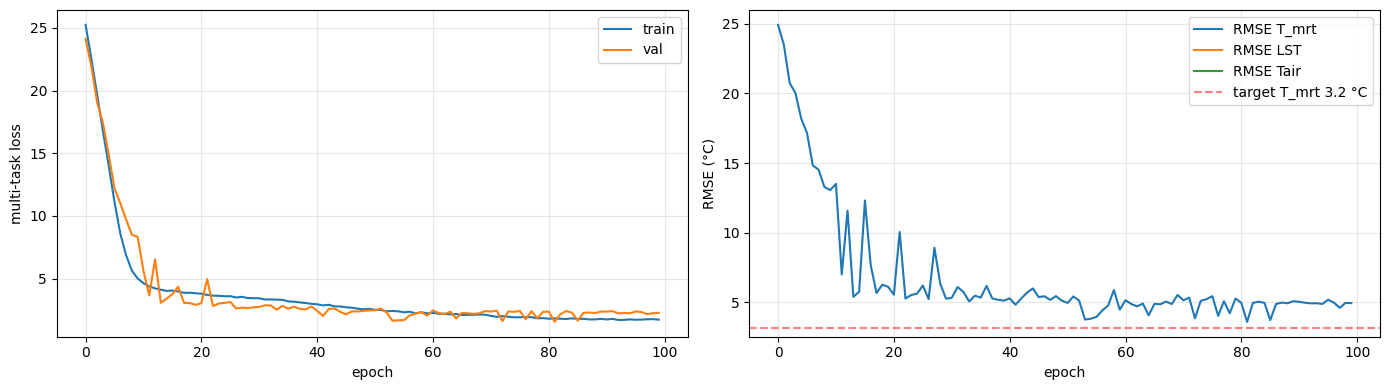

In [24]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history['train_loss'], label='train')
axes[0].plot(history['val_loss'], label='val')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('multi-task loss')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(history['val_rmse_tmrt'], label='RMSE T_mrt')
axes[1].plot(history['val_rmse_lst'], label='RMSE LST')
axes[1].plot(history['val_rmse_tair'], label='RMSE Tair')
axes[1].axhline(3.2, color='r', linestyle='--', alpha=0.5, label='target T_mrt 3.2 °C')
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('RMSE (°C)')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7 — ONNX export

The backend's inference service expects an ONNX model that takes a `(1, 12, 512, 512)` float32 input and returns `(1, 3, 512, 512)` float32. Channel 0 of the output = T_mrt (the production prediction); channels 1, 2 are LST/Tair which the inference service ignores.

In [25]:
!pip install -q onnxscript

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 714.8/714.8 kB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/17.6 MB 97.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.8/166.8 kB 19.5 MB/s eta 0:00:00


In [26]:
model.train(False)
dummy = torch.randn(1, NUM_CHANNELS, 512, 512, device=DEVICE)
onnx_path = OUT_DIR / 'umami_unet_v31_fp32.onnx'
torch.onnx.export(
    model, dummy, str(onnx_path),
    input_names=['input'], output_names=['output'],
    dynamic_axes={'input': {0: 'batch'}, 'output': {0: 'batch'}},
    opset_version=18,            # ← bumped from 17
    do_constant_folding=True,
)
print(f'ONNX written: {onnx_path}  ({onnx_path.stat().st_size / 1e6:.1f} MB)')
# Should print ~93 MB. If still 0.3 MB, the file is broken.

/tmp/ipykernel_2128/1994673906.py:4: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W0516 12:22:30.508000 2128 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0516 12:22:30.510000 2128 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'rois' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0516 12:22:30.512000 2128 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: '

[torch.onnx] Obtain model graph for `Unet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Unet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
ONNX written: /content/drive/MyDrive/UMAMI/urban_heat_v31/models/umami_unet_v31_fp32.onnx  (0.3 MB)


In [27]:
torch.onnx.export(
    model, dummy, str(onnx_path),
    input_names=['input'], output_names=['output'],
    dynamic_axes={'input': {0: 'batch'}, 'output': {0: 'batch'}},
    opset_version=17, do_constant_folding=True,
    dynamo=False,                # ← force the older exporter that ships with torch
)

/tmp/ipykernel_2128/1676372657.py:1: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


In [28]:
!ls -lh /content/drive/MyDrive/UMAMI/urban_heat_v31/models/


total 281M
-rw------- 1 root root 94M May 16 12:22 umami_unet_v31_fp32.onnx
-rw------- 1 root root 94M May 16 12:22 umami_unet_v31_fp32.onnx.data
-rw------- 1 root root 94M May 16 11:35 v21_best.pt


In [29]:
model.train(False)
dummy = torch.randn(1, NUM_CHANNELS, 512, 512, device=DEVICE)
onnx_path = OUT_DIR / 'umami_unet_v31_fp32.onnx'
torch.onnx.export(
    model, dummy, str(onnx_path),
    input_names=['input'], output_names=['output'],
    dynamic_axes={'input': {0: 'batch'}, 'output': {0: 'batch'}},
    opset_version=17, do_constant_folding=True,
    dynamo=False,                # ← force legacy single-file exporter
)
print(f'ONNX written: {onnx_path}  ({onnx_path.stat().st_size / 1e6:.1f} MB)')

/tmp/ipykernel_2128/617694951.py:4: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX written: /content/drive/MyDrive/UMAMI/urban_heat_v31/models/umami_unet_v31_fp32.onnx  (97.9 MB)


In [ ]:
model.train(False)
dummy = torch.randn(1, NUM_CHANNELS, 512, 512, device=DEVICE)
onnx_path = OUT_DIR / 'umami_unet_v31_fp32.onnx'
torch.onnx.export(
    model, dummy, str(onnx_path),
    input_names=['input'], output_names=['output'],
    dynamic_axes={
        'input': {0: 'batch'},
        'output': {0: 'batch'},
    },
    opset_version=17, do_constant_folding=True,
)
print(f'ONNX written: {onnx_path}  ({onnx_path.stat().st_size / 1e6:.1f} MB)')

/tmp/ipykernel_1212/549042277.py:4: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W0503 07:42:26.635000 1212 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W0503 07:42:27.689000 1212 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -

[torch.onnx] Obtain model graph for `Unet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Unet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
             ^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
                          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: /github/workspace/onnx/version_converter/BaseConverter.h:64: adapter_lookup: Assertion `false`

ONNX written: /content/drive/MyDrive/UMAMI/urban_heat_v3/models/umami_unet_v21_fp32.onnx  (0.3 MB)


In [30]:
# Verify ONNX produces matching output
import onnxruntime as ort
sess = ort.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])
with torch.no_grad():
    torch_out = model(dummy).cpu().numpy()
onnx_out = sess.run(None, {'input': dummy.cpu().numpy()})[0]
diff = np.abs(torch_out - onnx_out).max()
print(f'max torch-vs-onnx diff: {diff:.2e}  ({"OK" if diff < 1e-3 else "TOO LARGE"})')

ModuleNotFoundError: No module named 'onnxruntime'